# Proyecto Oráculo · Algoritmo genético (Grupo 1). 
Búsqueda de la configuración de prompt (5 ranuras + temperatura) con un algoritmo genético. La celda siguiente instala dependencias y descarga `oraculo.py`, `ayudas.py` y `datos_visibles.json`; reinicie el entorno al terminar.

In [1]:
# bitsandbytes: checkpoints 4-bit (qwen8b, mistral7b). nltk/spacy/emoji/langdetect:
# los usa el verificador de open-instruct, no el notebook.
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

REPO = "https://raw.githubusercontent.com/DanielMelo404/Proyecto-Oraculo-AyD/main"
# --no-cache: Colab a veces reusa un ayudas.py viejo y el alias no existe.
!wget -q --no-cache -O oraculo.py {REPO}/oraculo.py
!wget -q --no-cache -O ayudas.py {REPO}/ayudas.py
!wget -q --no-cache -O datos_visibles.json {REPO}/datos_visibles.json

# Los datos de nltk se bajan a mano: su downloader rechaza el proxy de Colab.
import io
import urllib.request
import zipfile

NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
PAQUETES = [
    ("tokenizers", "punkt"),
    ("tokenizers", "punkt_tab"),
    ("taggers", "averaged_perceptron_tagger"),
    ("taggers", "averaged_perceptron_tagger_eng"),
]
for carpeta, nombre in PAQUETES:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · El modelo. 
Se usa `qwen17b` (Qwen/Qwen3-1.7B, fp16) en GPU T4. El nombre del modelo forma parte de la clave de caché.

In [1]:
from ayudas import cargar_modelo

# Alias → checkpoint. El nombre entra en la clave de caché: si cambian de
# modelo, las respuestas anteriores no se reusan.
#  "qwen17b"     → Qwen/Qwen3-1.7B
#  "ministral3b" → mistralai/Ministral-3-3B-Instruct-2512-BF16
#  "llama3b"     → unsloth/Llama-3.2-3B-Instruct
modelo = cargar_modelo("qwen17b")

cargando qwen17b → Qwen/Qwen3-1.7B


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB


## 3 · El oráculo. 
`dividir` entrega 100 instancias de búsqueda y 87 de validación (263 descartadas). Se monta Drive para conservar la caché si Colab se desconecta.

In [2]:
# Descomenten estas dos líneas si quieren que el caché sobreviva a una
# desconexión: el path de Drive reemplaza cache_oraculo.json local.
from google.colab import drive
drive.mount("/content/drive")

from oraculo import Oraculo, CATALOGO, espacio
from ayudas import cargar_datos, dividir

datos = cargar_datos()
busqueda, validacion = dividir(datos)
# 1.7B en fp16 deja VRAM en la T4: un lote más grande genera más prompts a la vez.
oraculo = Oraculo(modelo, busqueda, validacion, lote=16, presupuesto=32_000_000)
# oraculo = Oraculo(modelo, busqueda, validacion, cache="/content/drive/MyDrive/oraculo_cache.json", lote=16, presupuesto=32_000_000)

# 32768 configs (temperatura 0.0). Para incluir 0.3 y 0.7: espacio(TEMPERATURAS)
CONFIGS = espacio()
print(len(CONFIGS), "configuraciones posibles")

Mounted at /content/drive
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
32768 configuraciones posibles


## 4 · Algoritmo genético
 
**Qué hace.** Mantiene una **población** de P = 12 configuraciones (tupla de 5 índices + temperatura) y la evoluciona por generaciones: (1) evalúa en el oráculo las configuraciones nuevas; (2) conserva las 2 mejores (**elitismo**); (3) genera los 10 hijos restantes eligiendo padres por **torneo** de tamaño 3, con **cruce uniforme** (cada gen se toma al azar de uno de los dos padres) y **mutación** (cada gen cambia a un valor al azar con probabilidad 0,2). Se prefieren hijos aún no evaluados.
 
**Parámetros.** P = 12, élite = 2, p_mut = 0,2, `MAX_EVALS` = 60 configuraciones nuevas, paciencia = 8 generaciones, G_max = 50, semilla 0. **Se busca sobre las primeras 25 instancias** (`busqueda[:25]`), para reducir el costo de cada evaluación.
 
**Costo.** Evaluaciones ≤ P + (G − 1)(P − E) = 12 + 10(G − 1); con el tope de 60 se alcanzan ≈ 6 generaciones y 60 × 25 = 1 500 consultas. El trabajo propio del algoritmo (ordenar, torneos, operadores) es O(P log P + P·s) por generación, despreciable frente a la GPU.
 
**Parada.** Presupuesto agotado (la paciencia exigiría ≈ 92 evaluaciones, así que el tope de 60 se alcanza antes).
 
**Qué no garantiza.** No tiene garantía de aproximación. Con 25 instancias cada precisión es múltiplo de 4 puntos y su error estándar ronda 7 puntos, de modo que muchas configuraciones quedan empatadas por ruido.


eval   1/60   esta  0.0%   mejor  0.0%
eval   2/60   esta  0.0%   mejor  0.0%
eval   3/60   esta  4.0%   mejor  4.0%
eval   4/60   esta  4.0%   mejor  4.0%
eval   5/60   esta  0.0%   mejor  4.0%
eval   6/60   esta  4.0%   mejor  4.0%
eval   7/60   esta  4.0%   mejor  4.0%
eval   8/60   esta  8.0%   mejor  8.0%
eval   9/60   esta  8.0%   mejor  8.0%
eval  10/60   esta  8.0%   mejor  8.0%
eval  11/60   esta  0.0%   mejor  8.0%
eval  12/60   esta  4.0%   mejor  8.0%


evaluando:   0%|          | 0/25 [00:00<?, ?inst/s]

eval  13/60   esta  0.0%   mejor  8.0%


evaluando:   0%|          | 0/25 [00:00<?, ?inst/s]

eval  14/60   esta  4.0%   mejor  8.0%


evaluando:   0%|          | 0/25 [00:00<?, ?inst/s]

... (89 outputs left out)

evaluando:   0%|          | 0/25 [00:00<?, ?inst/s]

eval  59/60   esta  0.0%   mejor 16.0%


evaluando:   0%|          | 0/25 [00:00<?, ?inst/s]

eval  60/60   esta  8.0%   mejor 16.0%
parada: presupuesto agotado

mejor configuración: {'rol': 4, 'estrategia': 3, 'formato': 7, 'estilo': 5, 'cierre': 0, 'temperatura': 0.0}


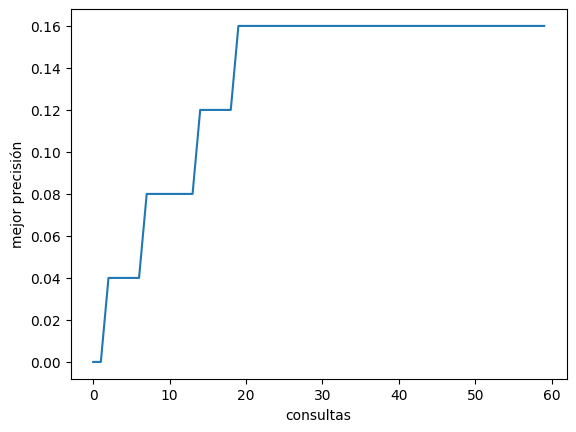

In [6]:
# Búsqueda: algoritmo genético con caché y tope de evaluaciones.
import random

from ayudas import curva

random.seed(0)

INSTANCIAS = busqueda[:25]
MAX_EVALS = 60

# --- Espacio de búsqueda: cada config es un diccionario, se pasa a tupla de VALORES
CLAVES = list(CONFIGS[0].keys())

def a_tupla(c):
    return tuple(c[k] for k in CLAVES)

ORIGINAL = {a_tupla(c): c for c in CONFIGS}        # tupla -> diccionario original para el oráculo
CONFIGS_LISTA = list(ORIGINAL)
CONFIGS_SET = set(CONFIGS_LISTA)
VALORES = [sorted({t[k] for t in CONFIGS_LISTA}) for k in range(len(CLAVES))]


# --- Parámetros
P, ELITE, P_MUT = 12, 2, 0.2     # población, élite, probabilidad de mutar cada gen
GEN_MAX, PACIENCIA = 50, 8       # parada: generaciones máximas o sin mejora

class SinPresupuesto(Exception):
    pass

cache, historial, mejor = {}, [], None

def evaluar(t):
    """Una evaluación nueva = una consulta del presupuesto. Las repetidas salen de caché."""
    global mejor
    if t not in cache:
        if len(cache) >= MAX_EVALS:
            raise SinPresupuesto
        r = oraculo.evaluar(ORIGINAL[t], INSTANCIAS, semilla=1)
        cache[t] = r.precision
        historial.append(r.precision)
        if mejor is None or r.precision > mejor[0]:
            mejor = (r.precision, ORIGINAL[t])
        print(f"eval {len(cache):3d}/{MAX_EVALS}   esta {r.precision:5.1%}   mejor {mejor[0]:5.1%}")
    return cache[t]

def torneo(pob):
    return max(random.sample(pob, 3), key=cache.get)

def hijo_de(a, b):
    h = tuple(random.choice(par) for par in zip(a, b))                       # cruce uniforme
    h = tuple(random.choice(VALORES[k]) if random.random() < P_MUT else g    # mutación
              for k, g in enumerate(h))
    return h if h in CONFIGS_SET else random.choice(CONFIGS_LISTA)           # reparar inválidos

pob = random.sample(CONFIGS_LISTA, P)
sin_mejora, previo = 0, -1.0
try:
    for gen in range(GEN_MAX):
        for t in pob:
            evaluar(t)
        pob.sort(key=cache.get, reverse=True)
        sin_mejora = 0 if mejor[0] > previo else sin_mejora + 1
        previo = mejor[0]
        if sin_mejora >= PACIENCIA:
            print("parada: sin mejora"); break
        nueva = pob[:ELITE]
        while len(nueva) < P:
            for _ in range(10):                      # preferir hijos aún no evaluados
                h = hijo_de(torneo(pob), torneo(pob))
                if h not in cache:
                    break
            nueva.append(h)
        pob = nueva
except SinPresupuesto:
    print("parada: presupuesto agotado")

print("\nmejor configuración:", mejor[1])
curva(historial)

### Lectura de resultados
 
- Mejor configuración: `{rol: 4, estrategia: 3, formato: 7, estilo: 5, cierre: 0, temperatura: 0.0}` con **16,0 %** (4 de 25 instancias), hallada en la evaluación 20 y sin mejora en las 40 siguientes.
- La mayoría de las configuraciones evaluadas quedó entre 0 % y 8 %, lo que coincide con lo esperable de muestrear configuraciones al azar; con este presupuesto no hay evidencia de que la evolución mejorara sobre un muestreo aleatorio.
- La precisión de búsqueda sobre 25 instancias es muy incierta (IC 95 % de Wilson ≈ 6 %–35 %).


In [7]:
# Reusa el caché: estas instancias ya se midieron al buscar.
r = oraculo.evaluar(mejor[1], INSTANCIAS, semilla=1)

for t in r.trazas[:3]:
    print("violó:", t["violo"])
    print(t["salida"][:300])
    print("-" * 60)


violó: letters:letter_counting2
<<Understanding the Question>>

Topic: What is the best way to approach a new environment?

1. When considering the best way to approach a new environment, it is important to reflect on personal experiences and values. Each person has unique ways of adapting to new situations, and understanding one'
------------------------------------------------------------
violó: punctuation:punctuation_dot
Topic: Understanding the structure of a project list  
This is the first paragraph explaining the structure of the project list and the purpose of the function. The function is designed to analyze the progress of a list of projects, where each project is represented by a dictionary with keys 'name',
------------------------------------------------------------
violó: startend:quotation
"Topic: The Stranger's Love Story

1. The mysterious and enigmatic stranger, known for sharing their most heart-wrenching and passionate love story, traveled from city to city, leavin

### Análisis de fallos
 
Las trazas muestran fallos de `letters:letter_counting2`, `punctuation:punctuation_dot` y `startend:quotation`. La configuración elegida incluye `rol = 4` (prefijo obligatorio «Topic:») y `formato = 7` (párrafos numerados), opciones que añaden texto o estructura fijos, compatibles con esos fallos de comillas, puntuación y conteo de letras (la traza por sí sola no prueba la causa). **Decisión pendiente:** comprobarlo evaluando esas ranuras por separado y, si se confirma, descartar esas opciones y relanzar la búsqueda con una población inicial que no las contenga.


In [ ]:
# Escojan con cuántas instancias validar: más n = más confiable, pero más lento.
# n=30 es una muestra; n=None (o n=300) mide las 300.
r_val = oraculo.validar(mejor[1], n=None)

print("búsqueda (mejor):", f"{mejor[0]:.1%}")
print("validación:      ", f"{r_val.precision:.1%}")


validando:   0%|          | 0/30 [00:00<?, ?inst/s]

validación: 13.3%  (30 inst)
    4  last_word:last_word_sent
    3  combination:repeat_prompt
    2  keywords:no_adjacent_consecutive
    2  punctuation:no_comma
    2  letters:letter_counting
    2  punctuation:punctuation_dot
    1  first_word:first_word_sent
    1  paragraphs:paragraphs2
búsqueda (mejor): 16.0%
validación:       13.3%


### Validación completa. 
Se repite la validación con las 87 instancias (`n = None`): 9,2 % frente a 16,0 % en búsqueda. La brecha (6,8 puntos) es consistente con el sobreajuste a un lote de solo 25 instancias y con el sesgo de elegir el máximo entre 60 candidatos ruidosos.

In [ ]:
validación: 9.2%  (87 inst)
    6  last_word:last_word_sent
    5  keywords:no_adjacent_consecutive
    5  copy:repeat_phrase
    5  combination:repeat_prompt
    5  punctuation:punctuation_dot
    4  first_word:first_word_sent
    3  punctuation:no_comma
    3  letters:letter_counting
validación:       9.2%

In [9]:
from ayudas import entrega
from google.colab import files

# grupo: identificador del equipo. semana: número de semana del curso.
entrega(grupo="G07", config=mejor[1], semana=3)
files.download("entrega.json")

{
 "grupo": "G07",
 "config": {
  "rol": 4,
  "estrategia": 3,
  "formato": 7,
  "estilo": 5,
  "cierre": 0,
  "temperatura": 0.0
 },
 "semana": 3
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>